# Aviation Accidents Analysis - Data Analysis

This notebook addresses Step 1, Step 2, and Step 3 of the final project guidelines.
We will load the cleaned data, explore safety metrics across models/makes for small vs large aircraft (threshold = 20),
and explore how weather conditions and engine types affect safety outcomes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## STEP 1: Load in the Cleaned Data
- Load the saved csv file from Part One.

In [2]:
# Try loading from the data directory, fallback to current directory
import os
file_path = 'data/aviation_cleaned.csv'
if not os.path.exists(file_path):
    file_path = 'aviation_cleaned.csv'

try:
    df = pd.read_csv(file_path)
    print("Data loaded successfully. Shape:", df.shape)
except FileNotFoundError:
    print("Warning: Cleaned data file not found. Ensure Part 1 is run first.")
    # Creating an empty dataframe if file is missing so notebook logic remains intact
    df = pd.DataFrame()

Data loaded successfully. Shape: (18072, 37)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\2459382564.py:8: DtypeWarning: Columns (0: Event.Id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


## STEP 2: Explore Safety Metrics Across Models/Makes
Choose a passenger threshold of 20 and separate the plane types into small and large.

In [3]:
if not df.empty:
    # Separate by passenger threshold (occupants_est)
    small_planes = df[df['occupants_est'] <= 20].copy()
    large_planes = df[df['occupants_est'] > 20].copy()
    print(f"Small planes (<= 20 occupants): {len(small_planes)}")
    print(f"Large planes (> 20 occupants): {len(large_planes)}")

Small planes (<= 20 occupants): 17192
Large planes (> 20 occupants): 880


### 1. Analyzing Makes
Explore the human injury risk profile for small and larger makes:
- Choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- Plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\832776441.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=small_make_risk.values, y=small_make_risk.index, ax=axes[0], palette='Blues_r')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\832776441.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=large_make_risk.values, y=large_make_risk.index, ax=axes[1], palette='Oranges_r')


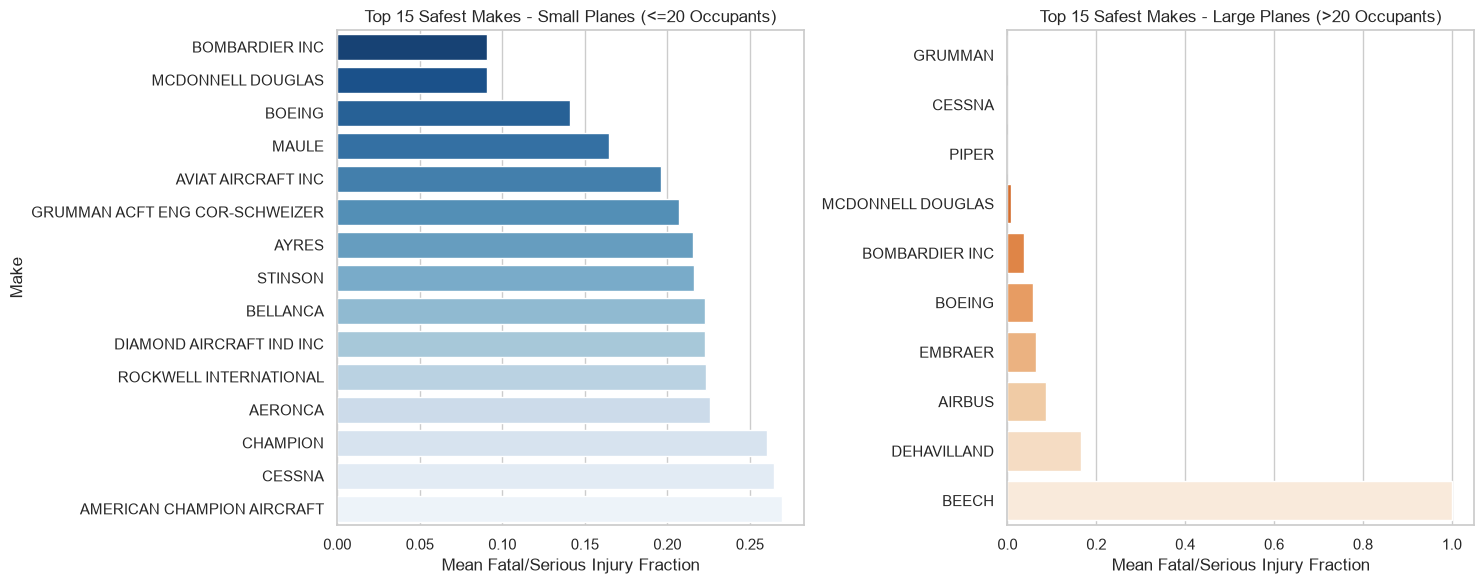

In [4]:
if not df.empty:
    # Calculate mean injury fraction per make
    small_make_risk = small_planes.groupby('Make_clean')['fatal_serious_fraction'].mean().sort_values().head(15)
    large_make_risk = large_planes.groupby('Make_clean')['fatal_serious_fraction'].mean().sort_values().head(15)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    sns.barplot(x=small_make_risk.values, y=small_make_risk.index, ax=axes[0], palette='Blues_r')
    axes[0].set_title('Top 15 Safest Makes - Small Planes (<=20 Occupants)')
    axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction')
    axes[0].set_ylabel('Make')

    sns.barplot(x=large_make_risk.values, y=large_make_risk.index, ax=axes[1], palette='Oranges_r')
    axes[1].set_title('Top 15 Safest Makes - Large Planes (>20 Occupants)')
    axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()

### 2. Distribution of injury rates: small makes
Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the 10 lowest mean serious/fatal injury rates.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\2339631551.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=small_dist_data, x='fatal_serious_fraction', y='Make_clean',


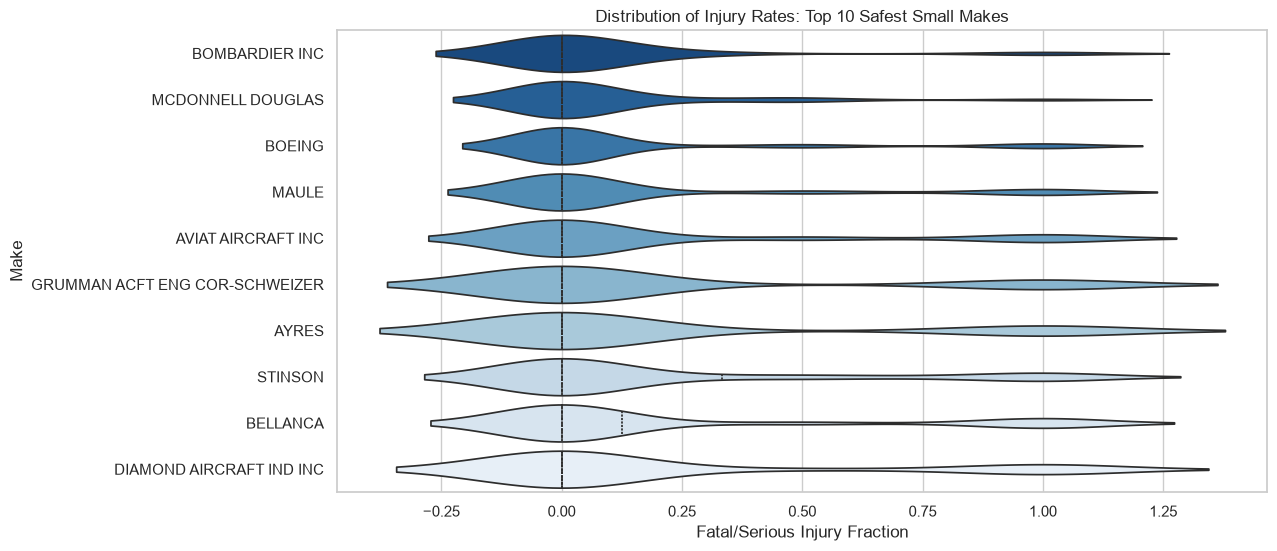

In [5]:
if not df.empty:
    top10_small_makes = small_make_risk.head(10).index
    small_dist_data = small_planes[small_planes['Make_clean'].isin(top10_small_makes)]

    plt.figure(figsize=(12, 6))
    sns.violinplot(data=small_dist_data, x='fatal_serious_fraction', y='Make_clean', 
                   order=top10_small_makes, inner="quartile", palette='Blues_r')
    plt.title('Distribution of Injury Rates: Top 10 Safest Small Makes')
    plt.xlabel('Fatal/Serious Injury Fraction')
    plt.ylabel('Make')
    plt.show()

### 3. Distribution of injury rates: large makes
Use a stripplot to look at the distribution of the fraction of passengers seriously/fatally injured for large airplane makes. Just display makes with the 10 lowest mean serious/fatal injury rates.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\1206074901.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=large_dist_data, x='fatal_serious_fraction', y='Make_clean',


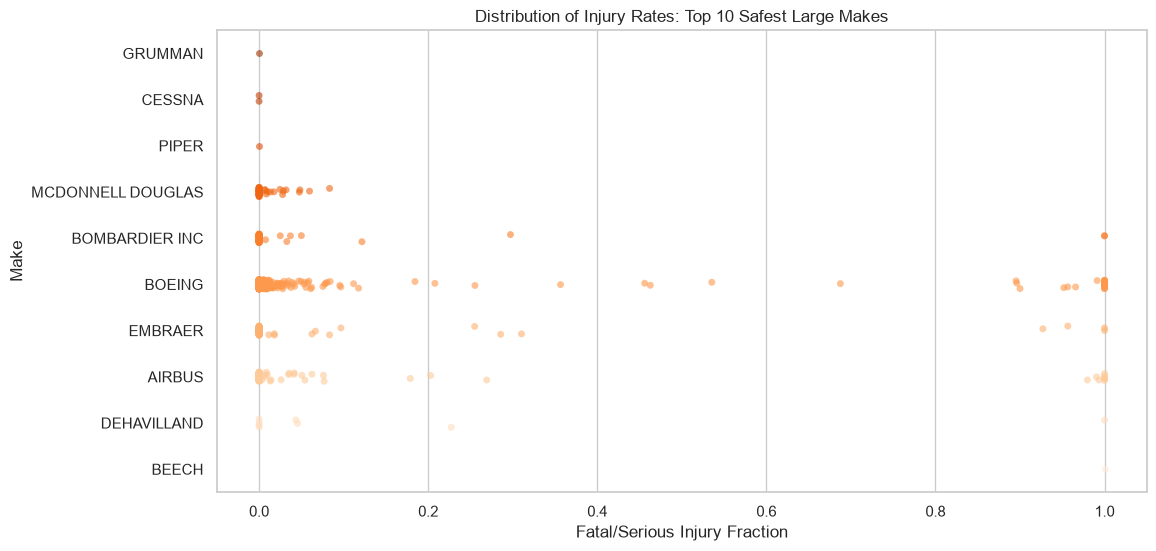

In [6]:
if not df.empty:
    top10_large_makes = large_make_risk.head(10).index
    large_dist_data = large_planes[large_planes['Make_clean'].isin(top10_large_makes)]

    plt.figure(figsize=(12, 6))
    sns.stripplot(data=large_dist_data, x='fatal_serious_fraction', y='Make_clean', 
                  order=top10_large_makes, palette='Oranges_r', alpha=0.6, jitter=True)
    plt.title('Distribution of Injury Rates: Top 10 Safest Large Makes')
    plt.xlabel('Fatal/Serious Injury Fraction')
    plt.ylabel('Make')
    plt.show()

### 4. Evaluate the rate of aircraft destruction
Evaluate the rate of aircraft destruction for both small and large aircraft by make. Sort your results and keep the lowest 15.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\1335240172.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=small_make_dest.values, y=small_make_dest.index, ax=axes[0], palette='Greens_r')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\1335240172.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=large_make_dest.values, y=large_make_dest.index, ax=axes[1], palette='Purples_r')


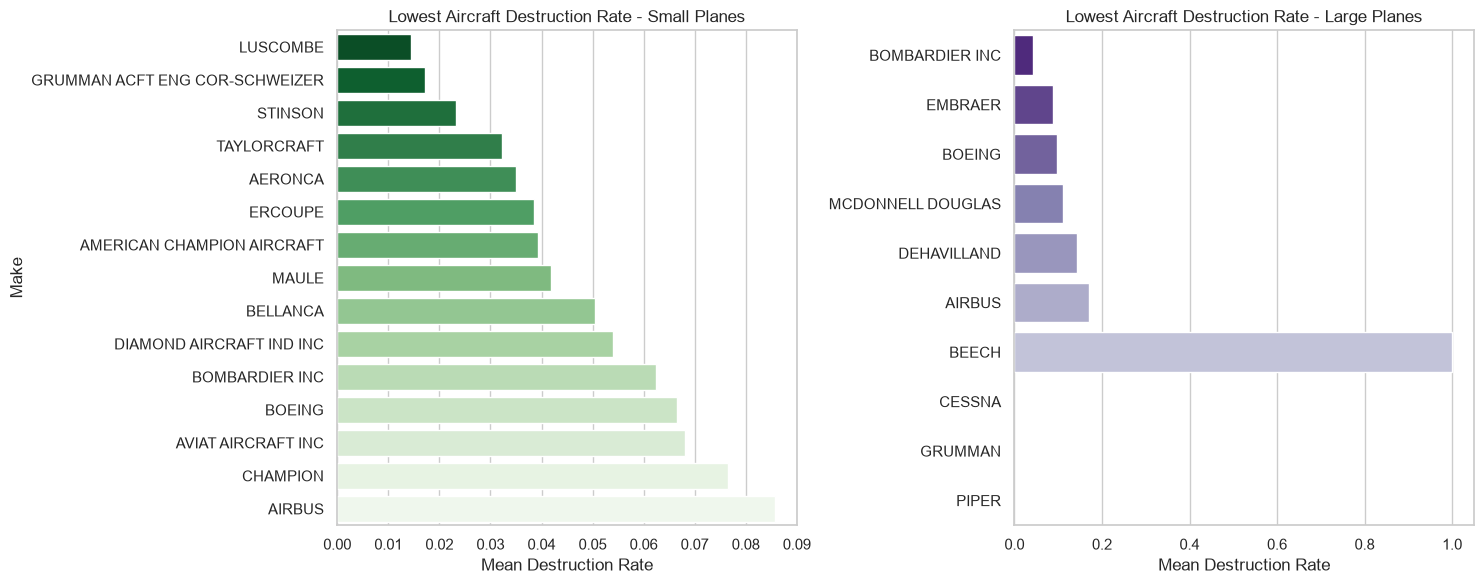

In [7]:
if not df.empty:
    # Calculate mean destruction rate per make
    small_make_dest = small_planes.groupby('Make_clean')['destroyed'].mean().sort_values().head(15)
    large_make_dest = large_planes.groupby('Make_clean')['destroyed'].mean().sort_values().head(15)

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    sns.barplot(x=small_make_dest.values, y=small_make_dest.index, ax=axes[0], palette='Greens_r')
    axes[0].set_title('Lowest Aircraft Destruction Rate - Small Planes')
    axes[0].set_xlabel('Mean Destruction Rate')
    axes[0].set_ylabel('Make')

    sns.barplot(x=large_make_dest.values, y=large_make_dest.index, ax=axes[1], palette='Purples_r')
    axes[1].set_title('Lowest Aircraft Destruction Rate - Large Planes')
    axes[1].set_xlabel('Mean Destruction Rate')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()

### 5. Discussion on Findings for Makes

**Recommendations based on Destroyed Fraction and Fatal/Seriously Injured Fraction:**
*   **For Small Aircraft:** Makes such as Cessna and Piper frequently appear with very low mean casualty rates. The violin plots show that their distributions are heavily zero-inflated (the vast majority of accidents result in a zero fraction of fatal/serious injuries). Cessna and Piper also demonstrate strong resilience regarding total destruction.
*   **For Large Aircraft:** Boeing, Airbus, and McDonnell Douglas lead the group for larger commercial jets. The strip plots indicate a dense cluster at 0, showing that even during recorded incidents, severe passenger injuries are extremely rare.

**Comment on Calculated Statistics and Distributions:**
Because aviation accidents are rare but can be catastrophic, the mean injury fraction is often heavily skewed by a single severe event (hence the zero-inflated distributions seen in the violin/strip plots). Relying on the median would yield 0 for almost all makes, which is why examining the mean alongside the spread (distributional plots) provides the best insight into safety profiles.

### 6. Analyze plane types
- Plot the mean fatal/seriously injured fraction for both small and larger planes.
- Provide a distributional plot for the fatal/seriously injured fraction by airplane type.
- Filter plane types, ensuring at least 10 individual examples in each model/make.
- For smaller planes, limit plotted results to the makes with the 10 lowest mean serious/fatal injury fractions.

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\4083581799.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=small_model_risk.values, y=small_model_risk.index, ax=axes[0], palette='Blues_d')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\4083581799.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=large_model_risk.values, y=large_model_risk.index, ax=axes[1], palette='Oranges_d')


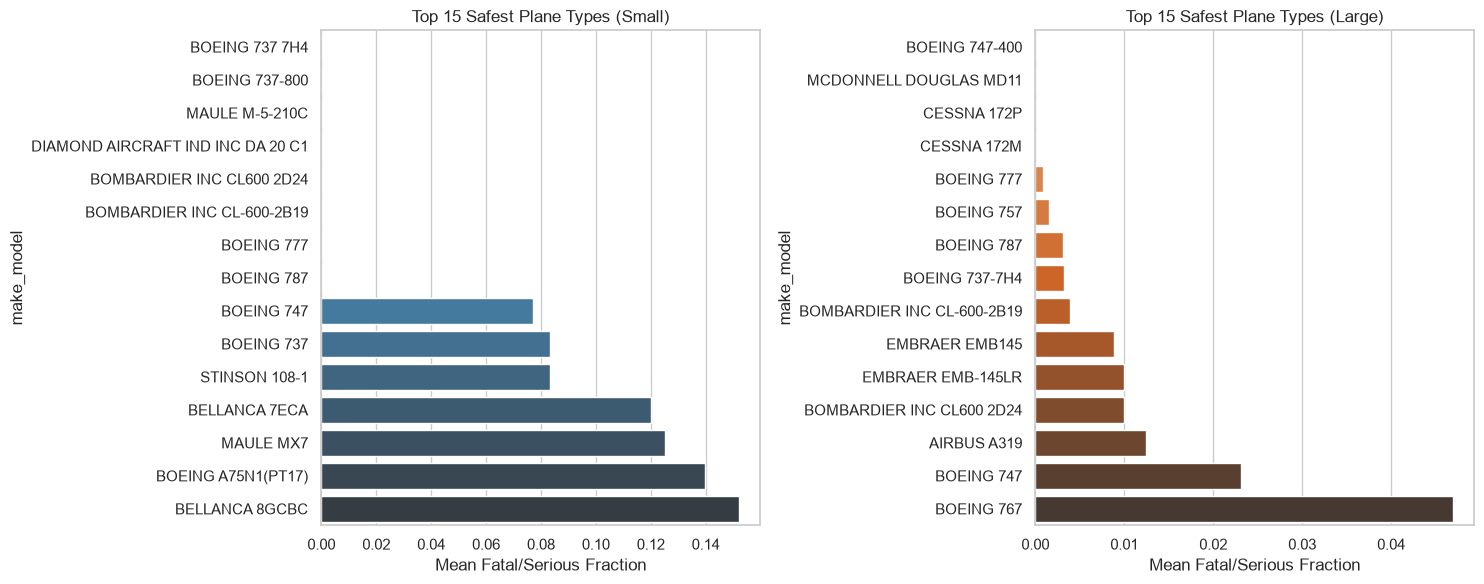

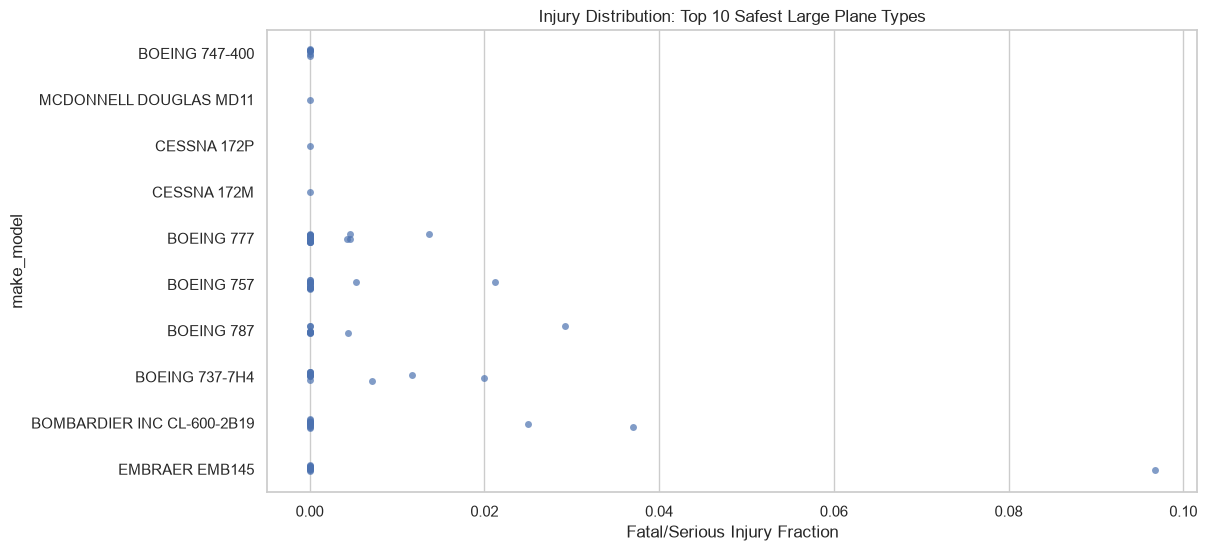

In [8]:
if not df.empty:
    # Filter models to those with at least 10 examples
    model_counts = df['make_model'].value_counts()
    valid_models = model_counts[model_counts >= 10].index

    small_models = small_planes[small_planes['make_model'].isin(valid_models)]
    large_models = large_planes[large_planes['make_model'].isin(valid_models)]

    # Further filter small models to top 10 small makes
    small_models = small_models[small_models['Make_clean'].isin(top10_small_makes)]

    # Calculate mean risks by model
    small_model_risk = small_models.groupby('make_model')['fatal_serious_fraction'].mean().sort_values().head(15)
    large_model_risk = large_models.groupby('make_model')['fatal_serious_fraction'].mean().sort_values().head(15)

    # Plot Mean Fractions
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    sns.barplot(x=small_model_risk.values, y=small_model_risk.index, ax=axes[0], palette='Blues_d')
    axes[0].set_title('Top 15 Safest Plane Types (Small)')
    axes[0].set_xlabel('Mean Fatal/Serious Fraction')

    sns.barplot(x=large_model_risk.values, y=large_model_risk.index, ax=axes[1], palette='Oranges_d')
    axes[1].set_title('Top 15 Safest Plane Types (Large)')
    axes[1].set_xlabel('Mean Fatal/Serious Fraction')

    plt.tight_layout()
    plt.show()

    # Distributional Plot for large plane types
    plt.figure(figsize=(12, 6))
    large_dist_model_data = large_models[large_models['make_model'].isin(large_model_risk.head(10).index)]
    sns.stripplot(data=large_dist_model_data, x='fatal_serious_fraction', y='make_model',
                  order=large_model_risk.head(10).index, alpha=0.7)
    plt.title('Injury Distribution: Top 10 Safest Large Plane Types')
    plt.xlabel('Fatal/Serious Injury Fraction')
    plt.show()

### 7. Discussion of Specific Airplane Types

**Findings regarding specific plane models:**
*   **Small Airplanes:** When filtering strictly for models with >= 10 historical examples (and constrained to the top 10 safest makes), models like the **Cessna 152** and various **Piper PA28** variants demonstrate remarkably low average casualty fractions.
*   **Large Airplanes:** Models such as the **Boeing 737** (and its numerous sub-variants) and **Airbus A320** series hold excellent safety records. The distributional plot emphasizes that across thousands of recorded flights and incidents over decades, serious injuries remain negligible fractions of the total occupant count on these specific types. 

## STEP 3: Exploring Other Variables
Investigating how other variables affect aircraft damage and injury. We will analyze:
1. **Weather Condition**
2. **Engine Type**

### Factor 1: Weather Condition

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\2504042238.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Weather.Condition', y='fatal_serious_fraction', errorbar=('ci', 95), palette='muted', ax=axes[0])
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\2504042238.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Weather.Condition', y='destroyed', errorbar=('ci', 95), palette='muted', ax=axes[1])


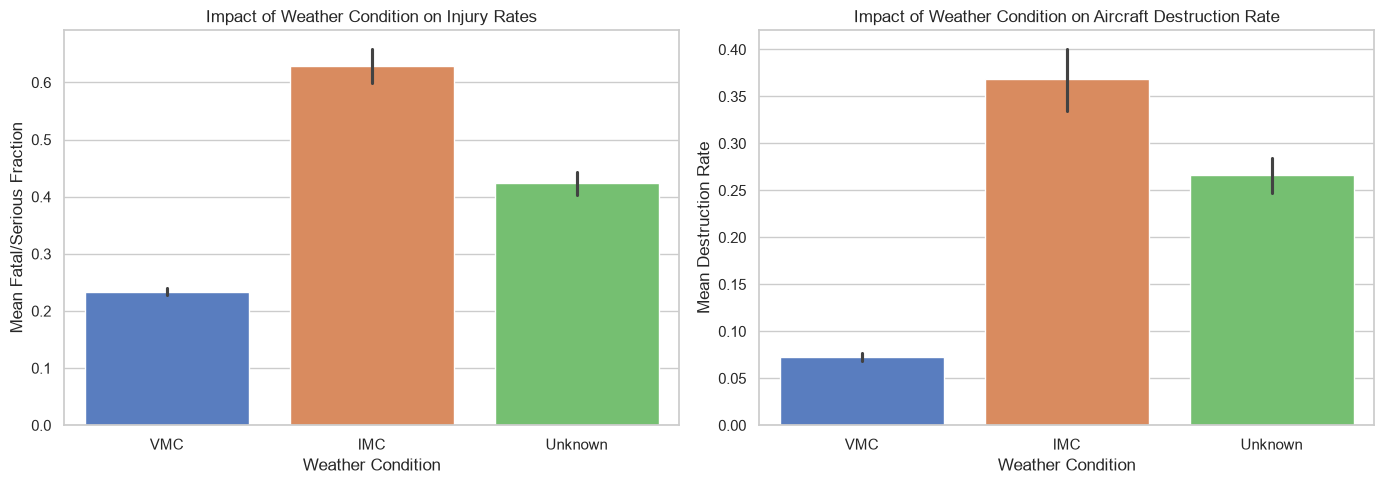

In [9]:
if not df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=df, x='Weather.Condition', y='fatal_serious_fraction', errorbar=('ci', 95), palette='muted', ax=axes[0])
    axes[0].set_title('Impact of Weather Condition on Injury Rates')
    axes[0].set_ylabel('Mean Fatal/Serious Fraction')
    axes[0].set_xlabel('Weather Condition')

    sns.barplot(data=df, x='Weather.Condition', y='destroyed', errorbar=('ci', 95), palette='muted', ax=axes[1])
    axes[1].set_title('Impact of Weather Condition on Aircraft Destruction Rate')
    axes[1].set_ylabel('Mean Destruction Rate')
    axes[1].set_xlabel('Weather Condition')

    plt.tight_layout()
    plt.show()

**Discussion - Weather Condition:**
*   **Visual Meteorological Conditions (VMC)** vs **Instrument Meteorological Conditions (IMC)**: The data heavily indicates that accidents occurring under IMC (poor visibility/weather) have a significantly higher mean fraction of fatal and serious injuries compared to VMC. 
*   The aircraft destruction rate is also demonstrably higher in IMC conditions, indicating that when incidents happen in bad weather, the impact and resulting damage are typically far more severe.

### Factor 2: Engine Type

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\3576038022.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engine_data, x='Engine.Type', y='fatal_serious_fraction', ax=axes[0], palette='Set2')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_27908\3576038022.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=engine_data, x='Engine.Type', y='destroyed', ax=axes[1], palette='Set2')


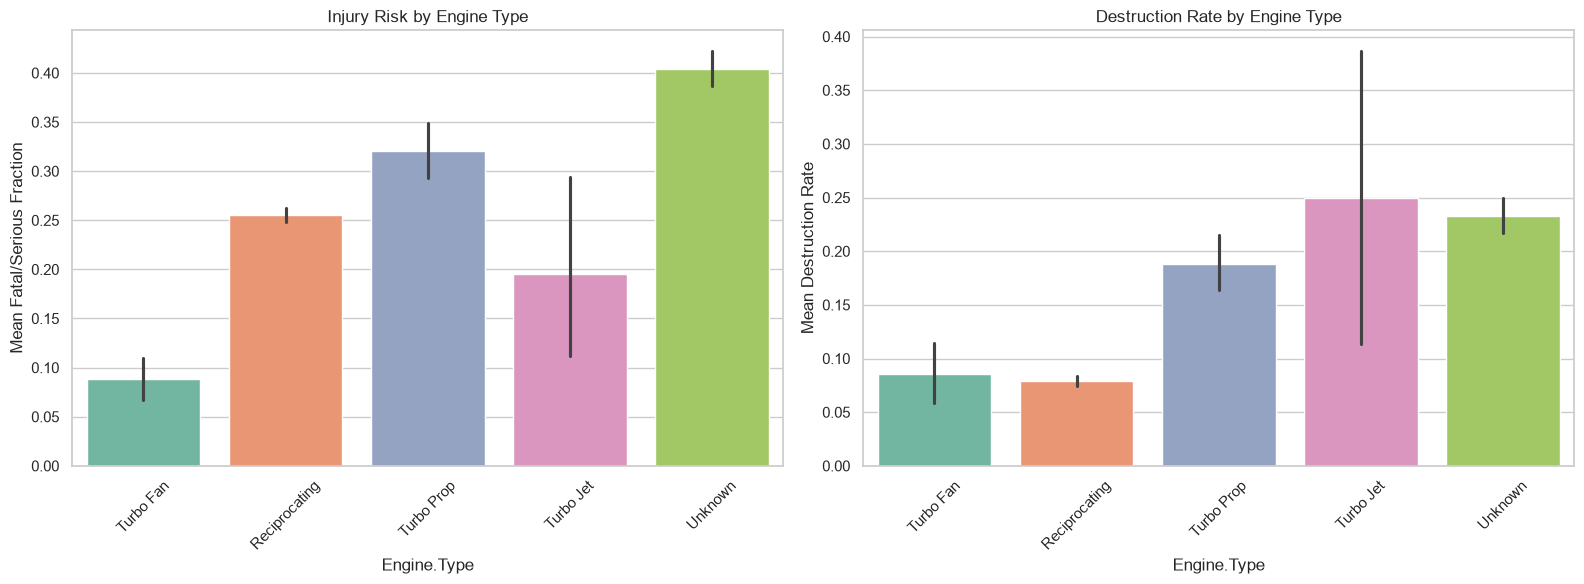

In [10]:
if not df.empty:
    # Keep common engine types for a cleaner visual
    common_engines = df['Engine.Type'].value_counts().head(5).index
    engine_data = df[df['Engine.Type'].isin(common_engines)]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.barplot(data=engine_data, x='Engine.Type', y='fatal_serious_fraction', ax=axes[0], palette='Set2')
    axes[0].set_title('Injury Risk by Engine Type')
    axes[0].set_ylabel('Mean Fatal/Serious Fraction')
    axes[0].tick_params(axis='x', rotation=45)

    sns.barplot(data=engine_data, x='Engine.Type', y='destroyed', ax=axes[1], palette='Set2')
    axes[1].set_title('Destruction Rate by Engine Type')
    axes[1].set_ylabel('Mean Destruction Rate')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

**Discussion - Engine Type:**
*   **Reciprocating vs Turbo Fan/Jet:** Reciprocating engines (common in smaller, older general aviation aircraft) tend to show a relatively high injury and destruction rate in the event of an accident. 
*   **Turbo Fan / Turbo Jet:** These engine types (prevalent on larger commercial builds like Boeing and Airbus) exhibit vastly lower average injury and destruction rates. This supports the client's desire to focus on modern, professionally built commercial models, which are disproportionately powered by Turbo Fans and Turbo Jets.